# Análise de Dados

## ETL com Python, SQLAlchemy e PostgreSQL

### Visão didática

Neste notebook vamos desenvolver todo o processo de análise em um único lugar.

Depois, o mesmo processo será organizado em arquivos `.py`, aproximando o projeto de uma arquitetura de produção.

O cenário possui um banco PostgreSQL:

```text
SUPERMARKET SALES                         DW_SUPERMERCADO
Fonte CSV                                 Banco de dados
      │                                        │
      │ ETL / Python                           ├── raw_vendas
      └───────────────────────────────────────>├── vendas_tratadas
                                               │
                                               ↓
                                          SQL / Análise

## Fontes

1. **supermarket_analysis**: arquivo CSV disponibilizado pelo projeto

## 1. Importação das bibliotecas

In [1]:
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text


## 2. Conexão com o PostgreSQL

Nesta etapa é configurada a conexão com o banco de dados
`dw_supermercado`.

O banco será utilizado para armazenar os dados brutos na tabela
`raw_vendas` e, posteriormente, os dados tratados na tabela
`vendas_tratadas`.

In [2]:
load_dotenv("./.env", override=True)

engine = create_engine(
    f"postgresql+psycopg2://{os.getenv('DB_USUARIO')}:{os.getenv('DB_SENHA')}"
    f"@{os.getenv('DB_HOST')}:{os.getenv('DB_PORTA')}/{os.getenv('DB_BANCO')}"
)

with engine.connect() as conn:
    resultado = conn.execute(
        text("SELECT current_database(), current_schema()")
    ).fetchone()

print("Conexões configuradas.")

Conexões configuradas.


# 1. Preparando o banco de dados

O banco `dw_supermercado` será utilizado para armazenar os dados:

```text
dw_supermercado
├── raw_vendas
└── vendas_tratadas

Gerado pelo arquivo 01_criar_banco.sql

# 2. EXTRACT — CSV → Raw

O Python lê o arquivo CSV e grava os dados na tabela `raw_vendas`.

In [3]:
df_vendas = pd.read_csv("../data/raw/supermarket_analysis.csv")

df_vendas.columns = [
    "invoice_id",
    "branch",
    "city",
    "customer_type",
    "gender",
    "product_line",
    "unit_price",
    "quantity",
    "tax_5_percent",
    "sales",
    "date",
    "time",
    "payment",
    "cogs",
    "gross_margin_percentage",
    "gross_income",
    "rating",
]

df_vendas.to_sql(
    "raw_vendas",
    engine,
    schema="public",
    if_exists="replace",
    index=False
)

print("Dados do CSV carregados para raw_vendas.")

Dados do CSV carregados para raw_vendas.


## Validação da carga

In [4]:
df_validacao = pd.read_sql(
    """
    SELECT *
    FROM raw_vendas
    LIMIT 5
    """,
    engine
)

df_validacao

,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5_percent,sales,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [5]:
df_contagem = pd.read_sql(
    """
    SELECT COUNT(*) AS quantidade_registros
    FROM raw_vendas
    """,
    engine
)

df_contagem

,quantidade_registros
0,1000


# 3. Tratamento e integração

Agora o processamento deixa de consultar o arquivo CSV.

Lê **somente a tabela raw_vendas**:

```text
raw_vendas
   ↓
limpeza
padronização
cálculos
integrações
validações
   ↓
vendas_tratadas

In [6]:
df_raw_vendas = pd.read_sql(
    """
    SELECT *
    FROM raw_vendas
    """,
    engine
)



print("Captura de dados de raw_vendas para DataFrames concluída.")
df_raw_vendas.head()

Captura de dados de raw_vendas para DataFrames concluída.


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5_percent,sales,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [7]:
print("Quantidade de registros:", len(df_raw_vendas))

print("Colunas disponíveis:")
print(df_raw_vendas.columns.tolist())

df_raw_vendas.head()

Quantidade de registros: 1000
Colunas disponíveis:
['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5_percent', 'sales', 'date', 'time', 'payment', 'cogs', 'gross_margin_percentage', 'gross_income', 'rating']


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5_percent,sales,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [8]:
df_vendas_tratadas = df_raw_vendas.copy()



duplicados = df_vendas_tratadas.duplicated(
    subset=["invoice_id"]
).sum()

df_vendas_tratadas = df_vendas_tratadas.drop_duplicates(
    subset=["invoice_id"]
).copy()

print("Duplicados removidos:", duplicados)
print("Registros após remoção:", len(df_vendas_tratadas))

df_vendas_tratadas.head()

Duplicados removidos: 0
Registros após remoção: 1000


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5_percent,sales,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [9]:
# Padronizar textos

colunas_texto = [
    "branch",
    "city",
    "customer_type",
    "gender",
    "product_line",
    "payment"
]

for coluna in colunas_texto:
    df_vendas_tratadas[coluna] = (
        df_vendas_tratadas[coluna].str.strip()
    )

print("Padronização dos textos concluída.")

df_vendas_tratadas.head()

Padronização dos textos concluída.


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5_percent,sales,date,time,payment,cogs,gross_margin_percentage,gross_income,rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [10]:
# Converter os horários
df_vendas_tratadas["time"] = pd.to_datetime(
    df_raw_vendas["time"].str.strip(),
    format="mixed",
    errors="coerce"
).dt.time

# Converter a coluna de data
df_vendas_tratadas["date"] = pd.to_datetime(
    df_raw_vendas["date"],
    format="%m/%d/%Y",
    errors="coerce"
)

print("Padronização de datas e horários concluída.")

Padronização de datas e horários concluída.


In [11]:
# Verificar valores ausentes
print("Valores ausentes por coluna:")
print(df_vendas_tratadas.isnull().sum())

print("\nTipos de dados:")
print(df_vendas_tratadas.dtypes)

print("\nTotal de registros:", len(df_vendas_tratadas))

print(
    "Invoice IDs duplicados:",
    df_vendas_tratadas["invoice_id"].duplicated().sum()
)

Valores ausentes por coluna:
invoice_id                 0
branch                     0
city                       0
customer_type              0
gender                     0
product_line               0
unit_price                 0
quantity                   0
tax_5_percent              0
sales                      0
date                       0
time                       0
payment                    0
cogs                       0
gross_margin_percentage    0
gross_income               0
rating                     0
dtype: int64

Tipos de dados:
invoice_id                            str
branch                                str
city                                  str
customer_type                         str
gender                                str
product_line                          str
unit_price                        float64
quantity                            int64
tax_5_percent                     float64
sales                             float64
date                       d

In [12]:
# Verificar os tipos das colunas numéricas
colunas_numericas = [
    "unit_price",
    "quantity",
    "tax_5_percent",
    "sales",
    "cogs",
    "gross_margin_percentage",
    "gross_income",
    "rating"
]

print(df_vendas_tratadas[colunas_numericas].dtypes)

unit_price                 float64
quantity                     int64
tax_5_percent              float64
sales                      float64
cogs                       float64
gross_margin_percentage    float64
gross_income               float64
rating                     float64
dtype: object


In [13]:
# Padronizar os nomes das colunas
df_vendas_tratadas = df_vendas_tratadas.rename(columns={
    "invoice_id": "id_venda",
    "branch": "filial",
    "city": "cidade",
    "customer_type": "tipo_cliente",
    "gender": "genero",
    "product_line": "linha_produto",
    "unit_price": "preco_unitario",
    "quantity": "quantidade",
    "tax_5_percent": "imposto",
    "sales": "valor_total",
    "date": "data_venda",
    "time": "hora_venda",
    "payment": "forma_pagamento",
    "cogs": "custo_mercadoria",
    "gross_margin_percentage": "margem_percentual",
    "gross_income": "receita_bruta",
    "rating": "avaliacao"
})

print("Colunas padronizadas:")
print(df_vendas_tratadas.columns.tolist())

print("\nTotal de registros:", len(df_vendas_tratadas))

df_vendas_tratadas.head()

Colunas padronizadas:
['id_venda', 'filial', 'cidade', 'tipo_cliente', 'genero', 'linha_produto', 'preco_unitario', 'quantidade', 'imposto', 'valor_total', 'data_venda', 'hora_venda', 'forma_pagamento', 'custo_mercadoria', 'margem_percentual', 'receita_bruta', 'avaliacao']

Total de registros: 1000


,id_venda,filial,cidade,tipo_cliente,genero,linha_produto,preco_unitario,quantidade,imposto,valor_total,data_venda,hora_venda,forma_pagamento,custo_mercadoria,margem_percentual,receita_bruta,avaliacao
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3


In [14]:
# Exportar dados tratados
df_vendas_tratadas.to_csv(
    "../data/processed/vendas_tratadas.csv",
    index=False,
    encoding="utf-8"
)

print("Arquivo vendas_tratadas.csv exportado com sucesso.")

Arquivo vendas_tratadas.csv exportado com sucesso.


In [15]:
# Carregar dados tratados no PostgreSQL
df_vendas_tratadas.to_sql(
    "vendas_tratadas",
    engine,
    if_exists="append",
    index=False
)

print("Dados carregados na tabela vendas_tratadas.")

Dados carregados na tabela vendas_tratadas.


In [16]:
with engine.connect() as conn:
    total = conn.execute(
        text("SELECT COUNT(*) FROM vendas_tratadas")
    ).scalar()

print("Total de registros na tabela:", total)

Total de registros na tabela: 3000


## 4. Resultados


### 4.1 Ler os dados tratados no arquivo vendas_tratadas.csv para análise

In [17]:
# Ler os dados tratados para análise
df_analise = pd.read_csv(
    "../data/processed/vendas_tratadas.csv"
)

print("Total de registros:", len(df_analise))

df_analise.head()

Total de registros: 1000


,id_venda,filial,cidade,tipo_cliente,genero,linha_produto,preco_unitario,quantidade,imposto,valor_total,data_venda,hora_venda,forma_pagamento,custo_mercadoria,margem_percentual,receita_bruta,avaliacao
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,2019-01-27,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3


In [18]:
# Criar tabela para armazenar as métricas
df_metricas = pd.DataFrame(
    columns=["metrica", "resultado", "valor"]
)

In [19]:
# Faturamento e quantidade de vendas por filial
df_faturamento_filial = (
    df_analise
    .groupby("filial")
    .agg(
        faturamento_total=("valor_total", "sum"),
        quantidade_vendas=("id_venda", "count"),
        valor_medio=("valor_total", "mean")
    )
    .reset_index()
    .sort_values(
        "faturamento_total",
        ascending=False
    )
)

# Identificar a filial com maior faturamento
filial = df_faturamento_filial.iloc[0]

print(
    f"A filial com maior faturamento é {filial['filial']}, "
    f"com R$ {filial['faturamento_total']:.2f}."
)

df_metricas.loc[len(df_metricas)] = [
    "Maior faturamento por filial",
    filial["filial"],
    round(filial["faturamento_total"], 2)
]

# Identificar a filial com mais vendas
filial = df_faturamento_filial.sort_values(
    "quantidade_vendas",
    ascending=False
).iloc[0]

print(
    f"A filial com mais vendas é {filial['filial']}, "
    f"com {filial['quantidade_vendas']} vendas."
)

df_metricas.loc[len(df_metricas)] = [
    "Filial com mais vendas",
    filial["filial"],
    filial["quantidade_vendas"]
]


A filial com maior faturamento é Giza, com R$ 110568.71.
A filial com mais vendas é Alex, com 340 vendas.


### 4.2 Faturamento e quantidade de vendas por filial

Nesta etapa, serão calculados o faturamento total, a quantidade de vendas e o valor médio das vendas por filial.


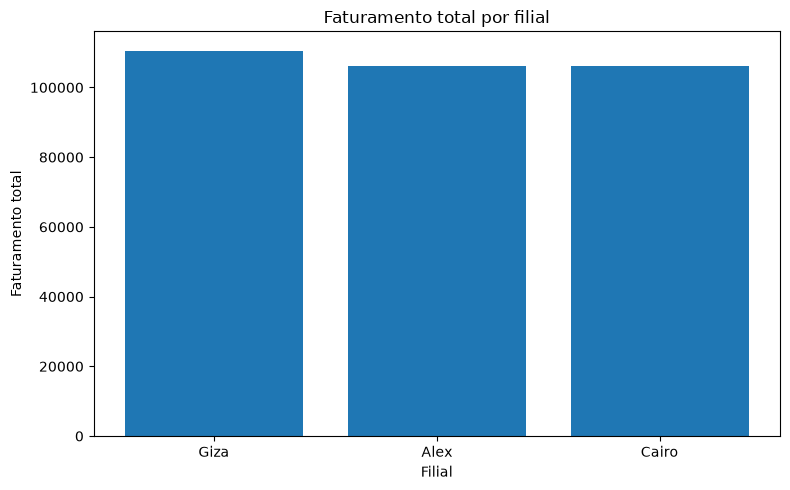

In [20]:
import matplotlib.pyplot as plt

# Gerar gráfico
plt.figure(figsize=(8, 5))

plt.bar(
    df_faturamento_filial["filial"],
    df_faturamento_filial["faturamento_total"]
)

plt.title("Faturamento total por filial")
plt.xlabel("Filial")
plt.ylabel("Faturamento total")
plt.tight_layout()

# Salvar gráfico
plt.savefig(
    "../resultados/graficos/faturamento_filiais.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.3. Faturamento e avaliação média por linha de produto

Nesta etapa, serão calculados o faturamento total e a avaliação média de cada linha de produto.


In [21]:
# Faturamento e avaliação média por linha de produto
df_analise_produtos = (
    df_analise
    .groupby("linha_produto")
    .agg(
        faturamento_total=("valor_total", "sum"),
        avaliacao_media=("avaliacao", "mean")
    )
    .reset_index()
    .sort_values(
        "faturamento_total",
        ascending=False
    )
)

# Produto com maior faturamento
produto = df_analise_produtos.iloc[0]

print(
    f"A linha de produto com maior faturamento é "
    f"{produto['linha_produto']}, "
    f"com R$ {produto['faturamento_total']:.2f}."
)

df_metricas.loc[len(df_metricas)] = [
    "Produto com maior faturamento",
    produto["linha_produto"],
    round(produto["faturamento_total"], 2)
]

# Produto com melhor avaliação
produto = df_analise_produtos.sort_values(
    "avaliacao_media",
    ascending=False
).iloc[0]

print(
    f"A linha de produto com melhor avaliação é "
    f"{produto['linha_produto']}, "
    f"com média {produto['avaliacao_media']:.2f}."
)

df_metricas.loc[len(df_metricas)] = [
    "Produto com melhor avaliação",
    produto["linha_produto"],
    round(produto["avaliacao_media"], 2)
]

A linha de produto com maior faturamento é Food and beverages, com R$ 56144.84.
A linha de produto com melhor avaliação é Food and beverages, com média 7.11.


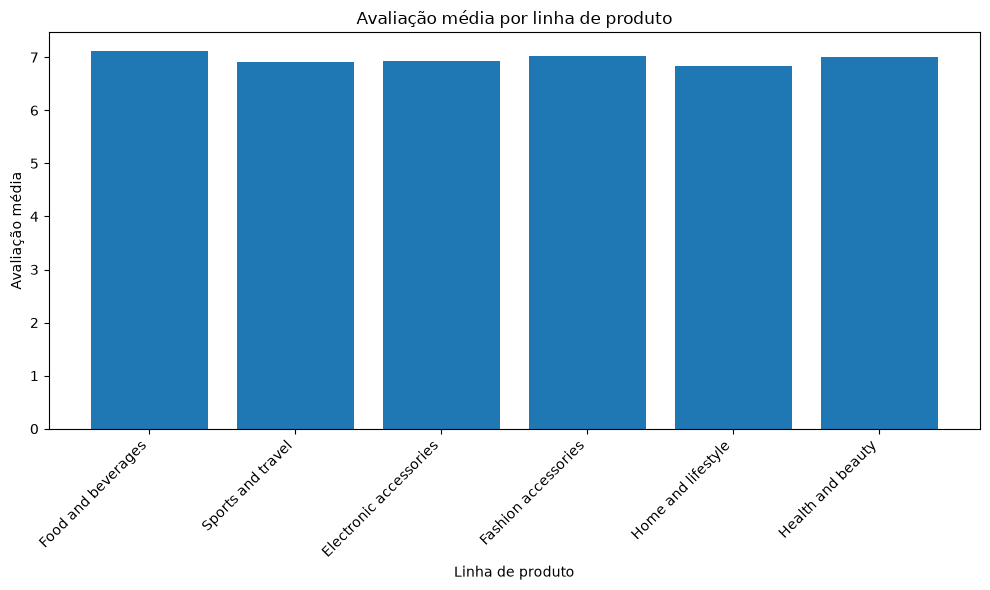

In [22]:
# Gráfico de avaliação média por linha de produto
plt.figure(figsize=(10, 6))

plt.bar(
    df_analise_produtos["linha_produto"],
    df_analise_produtos["avaliacao_media"]
)

plt.title("Avaliação média por linha de produto")
plt.xlabel("Linha de produto")
plt.ylabel("Avaliação média")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Salvar gráfico
plt.savefig(
    "../resultados/graficos/avaliacao_produtos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.4. Análise das formas de pagamento

Nesta etapa, será calculada a quantidade de vendas e o faturamento total por forma de pagamento.


In [23]:
# Quantidade de vendas por forma de pagamento
df_formas_pagamento = (
    df_analise
    .groupby("forma_pagamento")
    .agg(
        quantidade_vendas=("id_venda", "count"),
        faturamento_total=("valor_total", "sum")
    )
    .reset_index()
    .sort_values(
        "quantidade_vendas",
        ascending=False
    )
)


pagamento = df_formas_pagamento.iloc[0]

print(
    f"A forma de pagamento mais utilizada é "
    f"{pagamento['forma_pagamento']}, "
    f"com {pagamento['quantidade_vendas']} vendas."
)

df_metricas.loc[len(df_metricas)] = [
    "Forma de pagamento mais utilizada",
    pagamento["forma_pagamento"],
    pagamento["quantidade_vendas"]
]

A forma de pagamento mais utilizada é Ewallet, com 345 vendas.


### 4.4. Estatísticas gerais das vendas

Nesta etapa, serão calculados a quantidade de vendas, o faturamento total, o valor médio e o maior valor de venda.


In [24]:
# Estatísticas gerais das vendas
df_estatisticas_vendas = pd.DataFrame({
    "quantidade_vendas": [
        df_analise["id_venda"].count()
    ],
    "faturamento_total": [
        df_analise["valor_total"].sum()
    ],
    "valor_medio": [
        df_analise["valor_total"].mean()
    ],
    "maior_venda": [
        df_analise["valor_total"].max()
    ]
})

print(
    f"O valor médio das vendas é R$ "
    f"{df_estatisticas_vendas.iloc[0]['valor_medio']:.2f}."
)

df_metricas.loc[len(df_metricas)] = [
    "Valor médio das vendas",
    "Todas as vendas",
    round(df_estatisticas_vendas.iloc[0]["valor_medio"], 2)
]

print(
    f"A maior venda foi de R$ "
    f"{df_estatisticas_vendas.iloc[0]['maior_venda']:.2f}."
)

df_metricas.loc[len(df_metricas)] = [
    "Maior venda",
    "Maior valor registrado",
    round(df_estatisticas_vendas.iloc[0]["maior_venda"], 2)
]

O valor médio das vendas é R$ 322.97.
A maior venda foi de R$ 1042.65.


### 4.5 — Vendas por dia da semana

In [25]:
# Analisar vendas por dia da semana
df_vendas_dia = df_analise.copy()

df_vendas_dia["data_venda"] = pd.to_datetime(
    df_vendas_dia["data_venda"]
)

df_vendas_dia["dia_semana"] = (
    df_vendas_dia["data_venda"].dt.day_name()
)

df_vendas_por_dia = (
    df_vendas_dia
    .groupby("dia_semana")
    .agg(
        quantidade_vendas=("id_venda", "count"),
        faturamento_total=("valor_total", "sum")
    )
    .reset_index()
    .sort_values(
        "quantidade_vendas",
        ascending=False
    )
)

dia = df_vendas_por_dia.iloc[0]

print(
    f"O dia da semana com mais vendas foi "
    f"{dia['dia_semana']}, "
    f"com {dia['quantidade_vendas']} vendas."
)

df_metricas.loc[len(df_metricas)] = [
    "Dia da semana com mais vendas",
    dia["dia_semana"],
    dia["quantidade_vendas"]
]

O dia da semana com mais vendas foi Saturday, com 164 vendas.


### 4.6. Geração do arquivo metricas.csv

Tabela de Resultados


In [26]:
# Exportar métricas para CSV
df_metricas.to_csv(
    "../resultados/estatisticas/metricas.csv",
    index=False,
    encoding="utf-8"
)

print("Arquivo metricas.csv exportado com sucesso.")

df_metricas

Arquivo metricas.csv exportado com sucesso.


,metrica,resultado,valor
0,Maior faturamento por filial,Giza,110568.71
1,Filial com mais vendas,Alex,340.00
2,Produto com maior faturamento,Food and beverages,56144.84
3,Produto com melhor avaliação,Food and beverages,7.11
4,Forma de pagamento mais utilizada,Ewallet,345.00
5,Valor médio das vendas,Todas as vendas,322.97
6,Maior venda,Maior valor registrado,1042.65
7,Dia da semana com mais vendas,Saturday,164.00
